# Silage or Grain? A Field-Level Sentinel-2 Starter

This notebook demonstrates **one** open-data workflow for turning one corn-field boundary into a cloud-masked NDVI time series. It produces features that can support a **silage-like vs. grain-like** hypothesis; it does not create ground-truth harvest labels.

It is a starting point, not a prescribed data source or model. Teams are welcome to use any publicly available geospatial data, catalog, sensor, processing approach, or feature set that fits their hypothesis. Choose sources thoughtfully, validate what they measure and how they were produced, and document the evidence, limitations, and assumptions behind your method.

Read `data_sources.md` for alternative data pathways and validation guidance.

## 1. Install packages

Run once in a fresh environment. All data access in this notebook is public; no API key is required for the Microsoft Planetary Computer catalog.

In [1]:
%pip install geopandas matplotlib numpy odc-stac planetary-computer pystac-client xarray

Note: you may need to restart the kernel to use updated packages.


## 2. Supply a field boundary

Export one known or candidate corn field as `field_aoi.geojson` in this folder. The file must contain a polygon or multipolygon in a geographic CRS. A small single-field AOI keeps the first run fast.

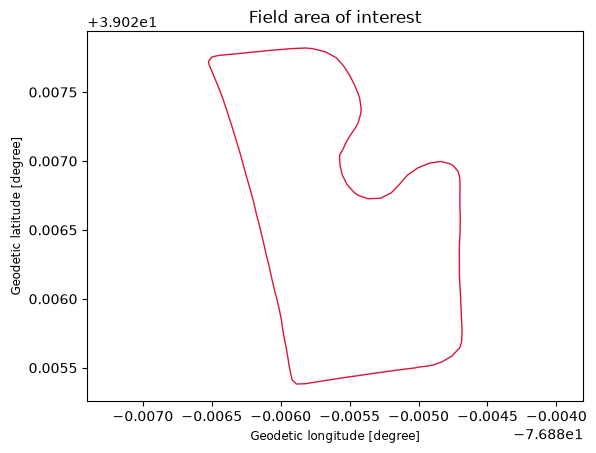

In [2]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import planetary_computer
from odc.stac import load
from pystac_client import Client

AOI_PATH = Path('field_aoi.geojson')
START_DATE = '2022-07-01'
END_DATE = '2022-11-30'
MAX_CLOUD_PERCENT = 40

if not AOI_PATH.exists():
    raise FileNotFoundError(
        'Create field_aoi.geojson next to this notebook, then rerun this cell.'
    )

aoi = gpd.read_file(AOI_PATH).to_crs('EPSG:4326')
if aoi.empty or not aoi.geometry.geom_type.isin(['Polygon', 'MultiPolygon']).all():
    raise ValueError('field_aoi.geojson must contain at least one polygon or multipolygon.')

aoi.plot(facecolor='none', edgecolor='crimson')
plt.title('Field area of interest')
plt.axis('equal');

## 3. Find public Sentinel-2 scenes

This is the first quality gate. Inspect scene count and cloud cover before calculating indices. If few clear scenes are returned, widen the date range or use Landsat as a second sensor.

In [3]:
catalog = Client.open('https://planetarycomputer.microsoft.com/api/stac/v1')
search = catalog.search(
    collections=['sentinel-2-l2a'],
    intersects=aoi.geometry.unary_union.__geo_interface__,
    datetime=f'{START_DATE}/{END_DATE}',
    query={'eo:cloud_cover': {'lt': MAX_CLOUD_PERCENT}},
)
items = list(search.item_collection())
print(f'Found {len(items)} scenes with less than {MAX_CLOUD_PERCENT}% scene cloud cover.')

if not items:
    raise RuntimeError('No scenes found. Check the AOI, dates, or cloud threshold.')

scene_summary = [
    (item.datetime.date(), item.properties.get('eo:cloud_cover'))
    for item in items
]
scene_summary[:10]

/var/folders/hx/4crb0yp11lbgywj7w6lnzw6m0000gn/T/ipykernel_13841/1692861063.py:4: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  intersects=aoi.geometry.unary_union.__geo_interface__,


Found 42 scenes with less than 40% scene cloud cover.


[(datetime.date(2022, 11, 26), 0.003309),
 (datetime.date(2022, 11, 21), 0.005222),
 (datetime.date(2022, 11, 19), 4.005062),
 (datetime.date(2022, 11, 14), 13.395345),
 (datetime.date(2022, 11, 9), 0.011954),
 (datetime.date(2022, 11, 1), 36.937505),
 (datetime.date(2022, 10, 30), 27.946946),
 (datetime.date(2022, 10, 27), 0.047024),
 (datetime.date(2022, 10, 22), 0.002427),
 (datetime.date(2022, 10, 20), 7.401993)]

## 4. Load red, near-infrared, and scene classification bands

The Sentinel-2 Scene Classification Layer (SCL) is used to reject cloud, cloud shadow, snow, and invalid pixels. This is deliberately conservative; inspect imagery if the field is small or results are sparse.

In [4]:
for item in items:
    planetary_computer.sign_inplace(item)

field_geometry = aoi.geometry.unary_union
cube = load(
    items,
    bands=['B04', 'B08', 'SCL'],
    geopolygon=field_geometry,
    crs='EPSG:32610',  # Replace with the local projected CRS for your study area.
    resolution=10,
    groupby='solar_day',
)
cube

/var/folders/hx/4crb0yp11lbgywj7w6lnzw6m0000gn/T/ipykernel_13841/23167880.py:4: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  field_geometry = aoi.geometry.unary_union


<xarray.Dataset> Size: 335kB
Dimensions:      (y: 29, x: 32, time: 30)
Coordinates:
  * y            (y) float64 232B 5.484e+06 5.484e+06 ... 5.483e+06 5.483e+06
  * x            (x) float64 256B 4.539e+06 4.539e+06 ... 4.54e+06 4.54e+06
  * time         (time) datetime64[us] 240B 2022-07-04T15:48:19.024000 ... 20...
    spatial_ref  int32 4B 32610
Data variables:
    B04          (time, y, x) float32 111kB 1.91e+03 1.95e+03 ... 1.268e+03
    B08          (time, y, x) float32 111kB 2.954e+03 3.462e+03 ... 2.534e+03
    SCL          (time, y, x) float32 111kB 5.0 4.0 4.0 4.0 ... 4.0 4.0 4.0 4.0

## 5. Calculate a cloud-masked field NDVI series

NDVI is $\frac{NIR - Red}{NIR + Red}$. The resulting line is a field average, not a harvest label. Look for the timing and rate of sustained decline after the seasonal maximum.

AttributeError: 'list' object has no attribute 'set'

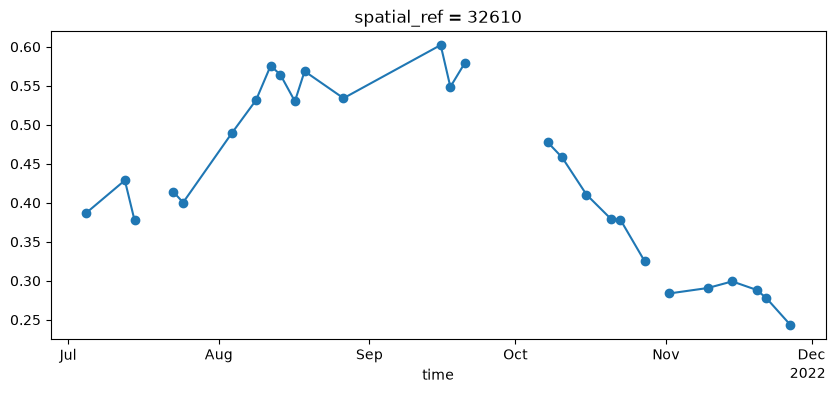

In [5]:
valid_scl = cube.SCL.isin([4, 5, 6, 7])
ndvi = (cube.B08 - cube.B04) / (cube.B08 + cube.B04)
field_ndvi = ndvi.where(valid_scl).median(dim=('x', 'y'), skipna=True)

field_ndvi.plot.line(marker='o', figsize=(10, 4))
ax = plt.gca()
ax.set(title='Cloud-masked median field NDVI', xlabel='Date', ylabel='NDVI')
ax.axvline(np.datetime64('2022-09-01'), color='grey', linestyle='--', alpha=0.5)
plt.show()

field_ndvi.to_dataframe(name='ndvi').dropna()

## 6. Derive transparent timing features

These features are a baseline, not a classifier. Build the same table for many fields, add defensible labels where available, and test whether timing separates holdout fields from other counties or years.

In [ ]:
series = field_ndvi.to_series().dropna().sort_index()
peak_date = series.idxmax()
peak_ndvi = series.max()
late_season = series[series.index >= '2022-09-01']

features = {
    'peak_date': peak_date.date().isoformat(),
    'peak_ndvi': float(peak_ndvi),
    'late_season_median_ndvi': float(late_season.median()),
    'observations_after_peak': int((series.index > peak_date).sum()),
}
features

Possible Next steps:
 1. Repeat for a field collection and multiple years.
 2. Add CDL eligibility, weather, red-edge/SWIR, and residue features.
 3. Compare an interpretable timing baseline with a model.
 4. Validate by geography and report abstentions and uncertainty.